# Benchmark des modèles inv-2-MR-Sort

Ce notebook **lit** les résultats calculés par `benchmark_run.py` (un JSON par modèle × fichier × répétition × pli, dans `benchmark_results/`) et les compare. Il ne relance pas lincs.

## Protocole
- **Validation croisée stratifiée à 5 plis**, répétée. Les plis dépendent seulement de `(fichier, répétition)` : tous les modèles sont évalués sur **les mêmes objets de test**, donc les comparaisons sont appariées.
- Chaque modèle s'entraîne sur 80 % des objets. Pour les variantes « ambigus », l'arrêt sur validation se fait **à l'intérieur** de ces 80 % : le pli de test ne sert jamais à choisir l'itération.
- Deux précisions sur le pli de test :
  - **oracle** : un objet est bon s'il est bien classé par *au moins un* des deux modèles. Cela suppose de connaître sa vraie catégorie : c'est une borne haute, comparable aux anciens chiffres ;
  - **honnête** : un petit arbre de décision, appris sur les objets d'entraînement pour prédire leur segment, choisit le modèle à appliquer à un objet de test **sans connaître son étiquette**.
- `1_modele` : un seul MR-Sort lincs sur tout le pli d'entraînement. Il sert de référence : le gain de la segmentation est l'écart avec lui.

## Lancer les calculs (dans un terminal)
```
.venv/bin/python benchmark_run.py --profile subset5 --jobs 4     # 5 fichiers
.venv/bin/python benchmark_run.py --profile strat   --jobs 3     # 23 fichiers stratifiés
.venv/bin/python benchmark_run.py --profile all     --jobs 4     # les 72 fichiers
```
Relancer la même commande ne recalcule rien : seuls les jobs manquants sont faits.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RESULTS = Path("../../results/benchmark_results")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def load_results(root=RESULTS):
    df = pd.DataFrame([json.loads(p.read_text()) for p in sorted(root.glob("*/*.json"))])
    df["config"] = df["dossier"]
    df["n"] = df["fichier"].str.extract(r"n(\d+)_")[0].astype(int)
    df["rep"] = df["fichier"].str.extract(r"rep(\d\d-\d\d)")[0]
    df["bruit"] = df["fichier"].str.extract(r"noise(\d\d)")[0].astype(int)
    df["ecart_oracle_honnete"] = df["oracle"] - df["honnete"]
    return df

res = load_results()
print(f"{len(res)} résultats, {res.fichier.nunique()} fichiers, {res.model.nunique()} modèles")

145 résultats, 8 fichiers, 2 modèles


## 1. Couverture
Nombre de plis calculés par modèle. Pour comparer deux modèles, on ne garde que les `(fichier, répétition, pli)` calculés par **tous** les modèles (section 3).

In [2]:
res.groupby("model").agg(plis=("fold", "size"), fichiers=("fichier", "nunique"), temps_total_min=("temps", lambda s: s.sum() / 60)).round(1)

,plis,fichiers,temps_total_min
model,,,
1_modele,115,8,7.9
2mrsort_base,30,6,24.0


## 2. Tableau principal
Moyenne sur tous les plis (± écart-type entre fichiers de la moyenne par fichier). **`gain_honnete`** est le gain réel face à un modèle unique : `honnete(modèle) − oracle(1_modele)`, avec `oracle = honnete` pour un seul modèle.

In [3]:
def main_table(res):
    per_file = res.groupby(["model", "fichier"])[["oracle", "honnete", "train", "ambigus", "petit_segment", "petit_attendu", "temps"]].mean()
    g = per_file.groupby("model")
    t = g.mean().round(3)
    t["oracle_std"] = g["oracle"].std().round(3)
    t["honnete_std"] = g["honnete"].std().round(3)
    t["train_moins_oracle"] = (t["train"] - t["oracle"]).round(3)
    if "1_modele" in t.index:
        t["gain_honnete_vs_1_modele"] = (t["honnete"] - t.loc["1_modele", "honnete"]).round(3)
    return t[["oracle", "oracle_std", "honnete", "honnete_std", "gain_honnete_vs_1_modele", "train", "train_moins_oracle", "ambigus", "petit_segment", "petit_attendu", "temps"]]

main_table(res)

,oracle,oracle_std,honnete,honnete_std,gain_honnete_vs_1_modele,train,train_moins_oracle,ambigus,petit_segment,petit_attendu,temps
model,,,,,,,,,,,
1_modele,0.638,0.056,0.638,0.056,0.000,0.707,0.069,0.707,0.000,0.375,3.906
2mrsort_base,0.872,0.048,0.651,0.071,0.013,0.948,0.076,0.329,0.413,0.375,48.078


Lecture :
- `oracle − honnete` mesure ce qui se perd quand on ne connaît pas l'étiquette. Un grand écart signifie que les segments retrouvés **ne se distinguent pas sur les features**.
- `train − oracle` est l'optimisme de la précision d'apprentissage (surapprentissage).
- `petit_segment` à comparer à `petit_attendu` : mesure grossière de la qualité de la partition (les CSV ne contiennent pas les vrais segments).

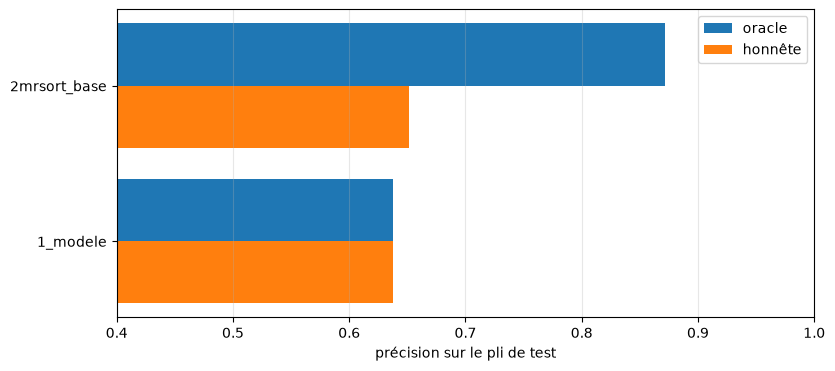

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
t = main_table(res).sort_values("honnete")
y = np.arange(len(t))
ax.barh(y + 0.2, t["oracle"], height=0.4, label="oracle")
ax.barh(y - 0.2, t["honnete"], height=0.4, label="honnête")
ax.set_yticks(y); ax.set_yticklabels(t.index); ax.set_xlim(0.4, 1); ax.set_xlabel("précision sur le pli de test")
ax.legend(); ax.grid(axis="x", alpha=0.3); plt.show()

## 3. Comparaison appariée de deux modèles
Les plis d'un même fichier sont corrélés. On calcule donc d'abord la différence **moyenne par fichier**, puis on fait l'intervalle de confiance (bootstrap) et le test de Wilcoxon **sur les fichiers**. Avec peu de fichiers (5), le test de Wilcoxon ne peut pas descendre sous p = 0,0625 : fiez-vous surtout à l'intervalle et au nombre de fichiers où le modèle gagne.

In [5]:
def paired(res, a, b, metric="honnete", n_boot=5000, seed=0):
    piv = res.pivot_table(index=["fichier", "repeat", "fold"], columns="model", values=metric)
    piv = piv[[a, b]].dropna()                                    # plis calculés par les deux modèles
    d = (piv[a] - piv[b]).groupby("fichier").mean()              # différence moyenne par fichier
    rng = np.random.default_rng(seed)
    boots = [rng.choice(d.values, len(d)).mean() for _ in range(n_boot)]
    p = stats.wilcoxon(d).pvalue if (d != 0).any() and len(d) > 1 else np.nan
    return dict(a=a, b=b, metrique=metric, fichiers=len(d), plis=len(piv), diff_moyenne=d.mean(),
                ic95_bas=np.percentile(boots, 2.5), ic95_haut=np.percentile(boots, 97.5),
                a_gagne_sur=f"{(d > 0).sum()}/{len(d)}", wilcoxon_p=p)

def compare_all(res, reference, metrics=("oracle", "honnete")):
    others = [m for m in res.model.unique() if m != reference]
    return pd.DataFrame([paired(res, m, reference, metric) for metric in metrics for m in others]).round(4)

compare_all(res, reference="2mrsort_base")

,a,b,metrique,fichiers,plis,diff_moyenne,ic95_bas,ic95_haut,a_gagne_sur,wilcoxon_p
0,1_modele,2mrsort_base,oracle,6,29,-0.2312,-0.2776,-0.1888,0/6,0.0312
1,1_modele,2mrsort_base,honnete,6,29,-0.0110,-0.0518,0.0199,3/6,1.0000


## 4. Où chaque modèle gagne ou perd
Précision (moyenne sur les plis) par groupe de fichiers. Remplacez `by` pour regrouper autrement : `config`, `type`, `n`, `rep`, `bruit`.

In [6]:
def by_group(res, by, metric="honnete"):
    return res.pivot_table(index=by, columns="model", values=metric, aggfunc="mean").round(3)

for by in ["config", "bruit", "rep", "n"]:
    print(f"--- honnête par {by}"); display(by_group(res, by))

--- honnête par config


model,1_modele,2mrsort_base
config,,
cr06_ca03,0.732,0.682
cr08_ca04,0.641,0.606
cr10_ca05,0.566,0.517


--- honnête par bruit


model,1_modele,2mrsort_base
bruit,,
0,0.655,0.692
10,0.595,0.571


--- honnête par rep


model,1_modele,2mrsort_base
rep,,
50-50,0.612,0.631
75-25,0.684,0.672


--- honnête par n


model,1_modele,2mrsort_base
n,,
300,0.690,0.670
600,0.630,0.633
1200,0.627,NaN


In [7]:
print("--- oracle par type et config"); display(by_group(res, ["type", "config"], "oracle"))
print("--- écart train − oracle par type et config (surapprentissage)")
res["train_moins_oracle"] = res["train"] - res["oracle"]
display(by_group(res, ["type", "config"], "train_moins_oracle"))

--- oracle par type et config


model             1_modele  2mrsort_base
type   config                           
type_a cr06_ca03     0.702         0.880
       cr08_ca04     0.712           NaN
       cr10_ca05     0.647           NaN
type_b cr06_ca03     0.781           NaN
       cr08_ca04     0.599         0.868
       cr10_ca05     0.505         0.750

--- écart train − oracle par type et config (surapprentissage)


model             1_modele  2mrsort_base
type   config                           
type_a cr06_ca03     0.074         0.087
       cr08_ca04     0.076           NaN
       cr10_ca05     0.059           NaN
type_b cr06_ca03     0.023           NaN
       cr08_ca04     0.047         0.051
       cr10_ca05     0.098         0.110

## 5. Précision d'apprentissage ou de test ?
Chaque point est un `(modèle, fichier)`. Au-dessus de la diagonale, la précision d'apprentissage est optimiste.

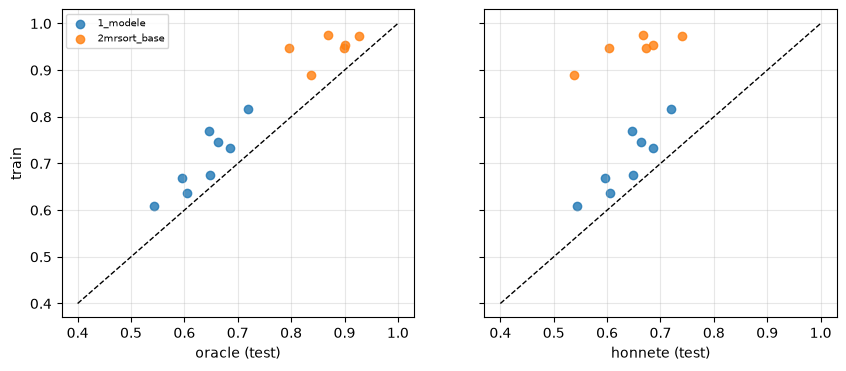

In [8]:
pf = res.groupby(["model", "fichier"])[["train", "oracle", "honnete"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col in zip(axes, ["oracle", "honnete"]):
    for m, g in pf.groupby("model"):
        ax.scatter(g[col], g["train"], label=m, alpha=0.8)
    ax.plot([0.4, 1], [0.4, 1], "k--", lw=1); ax.set_xlabel(f"{col} (test)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("train"); axes[0].legend(fontsize=7); plt.show()

## 6. Ajouter un nouveau modèle
1. Dans `benchmark_core.py`, écrire une fonction `fit_mon_modele(problem, df_train, y_train, seed, fast=False)` qui renvoie `FittedModel(models=[m0, m1], info={"train": ..., "val": ..., "iterations": ...})`. Ce sont des modèles lincs ; un modèle unique `[m]` est aussi accepté.
2. L'ajouter au dictionnaire `MODELS`.
3. `.venv/bin/python benchmark_run.py --profile subset5 --models mon_modele` : seuls ses jobs sont calculés (mêmes plis que les autres).
4. Relancer ce notebook : le modèle apparaît dans tous les tableaux. Comparer avec `compare_all(res, reference="2mrsort_base")`.